# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [17]:
VARIANT = 1   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 01 уже на месте: /content/data/variant_01
данные варианта: /content/data/variant_01
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [18]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 5.0.0 | numpy 2.1.3 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [19]:
# TODO: прочитайте variant.json и напечатайте его.
# Подсказка: путь собирайте от DATA_DIR, это объект Path, а не строка:
#   (DATA_DIR / "variant.json").read_text(encoding="utf-8") даёт текст файла,
#   json.loads(...) превращает текст в словарь.
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(variant_info)

# TODO: прочитайте labels.csv в DataFrame labels и покажите первые строки.
# Путь к файлу: DATA_DIR / "labels.csv"
labels = pd.read_csv(DATA_DIR / "labels.csv")
display(labels.head())


{'variant': 1, 'dataset_version': 'v1', 'source': 'release', 'breeds': ['Bengal', 'Egyptian_Mau', 'great_pyrenees', 'havanese'], 'species': {'Bengal': 'cat', 'Egyptian_Mau': 'cat', 'great_pyrenees': 'dog', 'havanese': 'dog'}, 'class_ids': {'Bengal': 0, 'Egyptian_Mau': 1, 'great_pyrenees': 2, 'havanese': 3}, 'names_ru': {'Bengal': 'бенгальская кошка', 'Egyptian_Mau': 'египетская мау', 'great_pyrenees': 'пиренейская горная собака', 'havanese': 'гаванский бишон'}, 'n_images': 795, 'n_boxes': 390, 'n_trimaps': 795, 'per_breed': {'Bengal': {'images': 200, 'boxes': 98, 'trimaps': 200}, 'Egyptian_Mau': {'images': 195, 'boxes': 92, 'trimaps': 195}, 'great_pyrenees': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'havanese': {'images': 200, 'boxes': 100, 'trimaps': 200}}, 'dataset': 'Oxford-IIIT Pet', 'dataset_url': 'https://www.robots.ox.ac.uk/~vgg/data/pets/', 'license': 'CC BY-SA 4.0', 'citation': 'O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar. Cats and Dogs. IEEE Conference on Compu

,filename,breed,species,class_id
0,Bengal_1.jpg,Bengal,cat,0
1,Bengal_2.jpg,Bengal,cat,0
2,Bengal_3.jpg,Bengal,cat,0
3,Bengal_4.jpg,Bengal,cat,0
4,Bengal_5.jpg,Bengal,cat,0


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [20]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

# TODO: прочитайте файл через cv2.imread(str(example_path)) в переменную bgr
bgr = cv2.imread(str(example_path))
print("type:", type(bgr))
print("shape:", bgr.shape)
print("dtype:", bgr.dtype)
print("min:", bgr.min())
print("max:", bgr.max())
print("pixel:", bgr[bgr.shape[0] // 2, bgr.shape[1] // 2])
# TODO: напечатайте type, shape, dtype, min, max и значение пикселя в центре кадра
#       bgr[bgr.shape[0] // 2, bgr.shape[1] // 2]


havanese_139.jpg
type: <class 'numpy.ndarray'>
shape: (476, 500, 3)
dtype: uint8
min: 0
max: 255
pixel: [ 45 118 180]


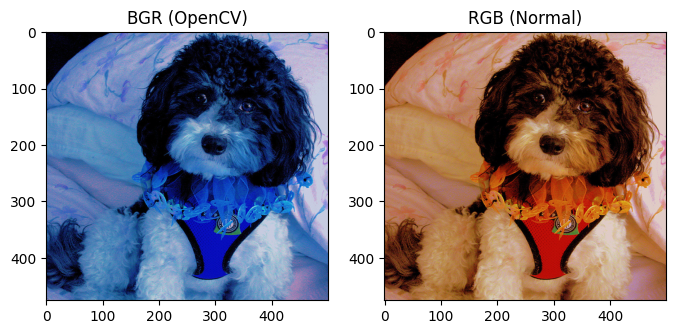

In [21]:
# TODO: переведите bgr в rgb через cv2.cvtColor(..., cv2.COLOR_BGR2RGB)
# TODO: покажите bgr и rgb рядом. Что случилось с цветами?
#   plt.subplot(1, 2, 1); plt.imshow(bgr)
#   plt.subplot(1, 2, 2); plt.imshow(rgb)
#   plt.show()
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(bgr); plt.title("BGR (OpenCV)")
plt.subplot(1, 2, 2); plt.imshow(rgb); plt.title("RGB (Normal)")
plt.show()


Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [22]:
# TODO: получите gray, resized (224x224) и flipped, напечатайте их shape
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)

print("gray shape:", gray.shape)
print("resized shape:", resized.shape)
print("flipped shape:", flipped.shape)

gray shape: (476, 500)
resized shape: (224, 224, 3)
flipped shape: (476, 500, 3)


In [23]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


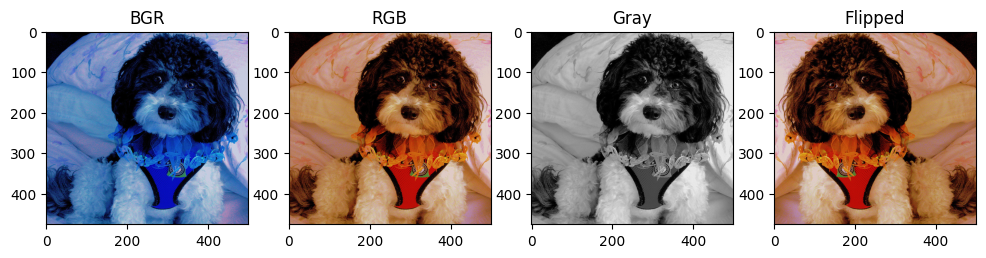

In [24]:
# TODO: 4 панели на одной фигуре: BGR как есть, RGB, серое, отражение
#   plt.figure(figsize=(12, 3))
#   plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
#   ... так же для rgb, gray (cmap="gray") и flipped
#   plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
plt.subplot(1, 4, 2); plt.imshow(rgb); plt.title("RGB")
plt.subplot(1, 4, 3); plt.imshow(gray, cmap="gray"); plt.title("Gray")
plt.subplot(1, 4, 4); plt.imshow(flipped); plt.title("Flipped")
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [25]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"], rec["height"] = im.size

    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()

    rec["breed"] = label_by_file.loc[p.name, "breed"]
    rec["species"] = label_by_file.loc[p.name, "species"]
    # TODO: через Image.open(p) запишите pil_format, mode, width, height

    # TODO: has_xml: существует ли XML_DIR / (p.stem + ".xml")

    # TODO: breed и species из label_by_file.loc[p.name]

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Bengal_1.jpg,.jpg,JPEG,RGB,600,901,False,Bengal,cat
1,Bengal_10.jpg,.jpg,JPEG,RGB,500,375,True,Bengal,cat
2,Bengal_100.jpg,.jpg,JPEG,RGB,500,333,True,Bengal,cat
3,Bengal_101.jpg,.jpg,JPEG,RGB,500,455,True,Bengal,cat
4,Bengal_102.jpg,.jpg,JPEG,RGB,334,500,True,Bengal,cat


In [26]:
# TODO: соберите словарь summary с главными числами и сохраните в results/summary.csv
# Минимум: число файлов, пород, кошек и собак, min/медиана/max ширины и высоты,
# сколько не RGB, сколько .jpg на самом деле не JPEG, сколько с XML.
summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": (info["species"] == "cat").sum(),
    "n_dogs": (info["species"] == "dog").sum(),
    "width_min": int(info["width"].min()),
    "width_median": int(info["width"].median()),
    "width_max": int(info["width"].max()),
    "height_min": int(info["height"].min()),
    "height_median": int(info["height"].median()),
    "height_max": int(info["height"].max()),
    "n_non_rgb": (info["mode"] != "RGB").sum(),
    "n_fake_jpg": ((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum(),
    "n_xml": info["has_xml"].sum(),
    # "n_files": len(info),
    # ...
}
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,1
1,n_files,795
2,n_breeds,4
3,n_cats,395
4,n_dogs,400
5,width_min,150
6,width_median,500
7,width_max,3264
8,height_min,112
9,height_median,375


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [27]:
# TODO: напечатайте файлы с mode != "RGB" и файлы с pil_format != "JPEG"
print("Не RGB режим:")
display(info[info["mode"] != "RGB"][["filename", "mode"]])

print("\nНесовпадение формата и расширения (fake jpg):")
display(info[info["pil_format"] != "JPEG"][["filename", "pil_format", "ext"]])

Не RGB режим:


,filename,mode
233,Egyptian_Mau_129.jpg,L
242,Egyptian_Mau_14.jpg,RGBA
285,Egyptian_Mau_186.jpg,RGBA



Несовпадение формата и расширения (fake jpg):


,filename,pil_format,ext
242,Egyptian_Mau_14.jpg,PNG,.jpg
259,Egyptian_Mau_156.jpg,PNG,.jpg
285,Egyptian_Mau_186.jpg,PNG,.jpg


In [28]:
# TODO: сравните формы массивов для одного проблемного файла
# Берем первый попавшийся проблемный файл из тех, что не RGB
bad_filename = info[info["mode"] != "RGB"]["filename"].iloc[0]
bad_path = IMG_DIR / bad_filename

shape_default = cv2.imread(str(bad_path)).shape
shape_unchanged = cv2.imread(str(bad_path), cv2.IMREAD_UNCHANGED).shape

print(f"Файл: {bad_filename}")
print("shape с флагом по умолчанию (cv2.imread):", shape_default)
print("shape с флагом IMREAD_UNCHANGED:", shape_unchanged)

Файл: Egyptian_Mau_129.jpg
shape с флагом по умолчанию (cv2.imread): (325, 299, 3)
shape с флагом IMREAD_UNCHANGED: (325, 299)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [29]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

# TODO: возьмите одно изображение с XML и напечатайте его боксы
# TODO: прочитайте его trimap: cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
#       и выведите np.unique(trimap)
# Находим первое попавшееся изображение, у которого есть XML-разметка
sample_row = info[info["has_xml"]].iloc[0]
sample_stem = Path(sample_row["filename"]).stem
sample_img_path = IMG_DIR / sample_row["filename"]
sample_xml_path = XML_DIR / (sample_stem + ".xml")
sample_trimap_path = TRIMAP_DIR / (sample_stem + ".png")

# Читаем и выпечатываем боксы
boxes = read_boxes(sample_xml_path)
print(f"Файл: {sample_row['filename']}")
print("Боксы из XML:", boxes)

# Читаем trimap с флагом IMREAD_UNCHANGED и выводим уникальные значения
trimap = cv2.imread(str(sample_trimap_path), cv2.IMREAD_UNCHANGED)
print("Уникальные значения в trimap:", np.unique(trimap))

Файл: Bengal_10.jpg
Боксы из XML: [(315, 60, 446, 219)]
Уникальные значения в trimap: [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

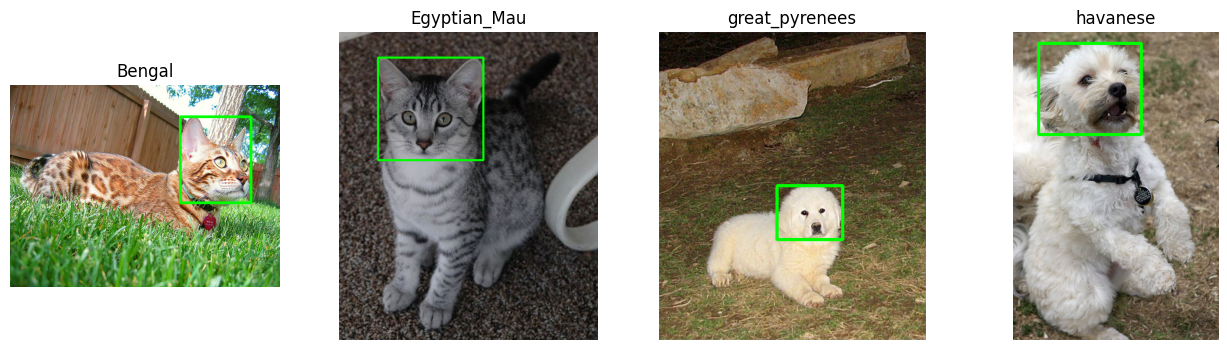

In [30]:
# TODO: для каждой породы возьмите одно фото с XML, нарисуйте бокс,
#       покажите все фото в один ряд через plt.subplot и сохраните в results/samples_grid.png
# Находим по одному фото с XML для каждой уникальной породы
breeds = info["breed"].unique()
sample_rows = [info[(info["breed"] == b) & (info["has_xml"])].iloc[0] for b in breeds]

plt.figure(figsize=(16, 4))

for i, row in enumerate(sample_rows):
    filename = row["filename"]
    stem = Path(filename).stem

    # Читаем картинку в RGB для корректного отображения через matplotlib
    img_bgr = cv2.imread(str(IMG_DIR / filename))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Читаем боксы и рисуем их на изображении
    boxes = read_boxes(XML_DIR / (stem + ".xml"))
    for box in boxes:
        x0, y0, x1, y1 = box
        cv2.rectangle(img_rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)

    # Выводим в подграфик
    plt.subplot(1, len(breeds), i + 1)
    plt.imshow(img_rgb)
    plt.title(row["breed"])
    plt.axis("off")

plt.savefig(RESULTS / "samples_grid.png", dpi=110)
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [31]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

       metric  value
      variant      1
      n_files    795
     n_breeds      4
       n_cats    395
       n_dogs    400
    width_min    150
 width_median    500
    width_max   3264
   height_min    112
height_median    375
   height_max   2606
    n_non_rgb      3
   n_fake_jpg      3
        n_xml    390
не хватает: ничего, все 3 файла на месте


In [32]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>